# Legacy vs. conformal wakefield simulation

This notebook compares the existing **legacy** STL discretization with the new
**conformal** geometry pipeline for the standard WAKIS cavity geometry.

Both simulations use exactly the same:

- cavity and shell STL files,
- Cartesian grid,
- beam parameters,
- wake length,
- PEC outer boundary conditions.

The material setup is:

- `cavity` → vacuum,
- `shell` → PEC,
- background → PEC.

The purpose is to compare the resulting wake potential and longitudinal impedance.
No analytical resonance frequencies are used because the cavity has smooth
pipe-to-cavity transitions and is not an ideal pillbox.


In [11]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pyvista as pv

from wakis import GridFIT3D, SolverFIT3D, WakeSolver

## Geometry and common simulation parameters

The notebook is assumed to live in the `notebooks` directory, so the existing
test STL files are addressed directly with relative paths.


In [ ]:
cavity_path = Path("../tests/stl/007_vacuum_cavity.stl")
shell_path = Path("../tests/stl/007_lossymetal_shell.stl")

stl_solids = {
    "cavity": str(cavity_path),
    "shell": str(shell_path),
}

stl_materials = {
    "cavity": "vacuum",
    "shell": "pec",
}

stl_material_types = {
    "cavity": "normal",
    "shell": "pec",
}

# stl_materials = {
#     "cavity": "vacuum",
#     "shell": [10.0, 1.0,10.0],
# }

# stl_material_types = {
#     "cavity": "normal",
#     "shell": "normal",
# }

solids = pv.read(cavity_path) + pv.read(shell_path)
xmin, xmax, ymin, ymax, zmin, zmax = solids.bounds

# Same Cartesian mesh for both simulations.
Nx = 20
Ny = 20
Nz = 60

# Beam parameters.
sigmaz = 10e-2
q = 1e-9
beta = 1.0

xsource = 0.0
ysource = 0.0
xtest = 0.0
ytest = 0.0

# Wake calculation.
wakelength = 100.0
skip_cells = 5

# Closed PEC computational domain.
bc_low = ["pec", "pec", "pec"]
bc_high = ["pec", "pec", "pec"]

dtype = np.float32

results_root = Path("_conformal_pillbox_wake")
results_root.mkdir(exist_ok=True)

## Legacy simulation

The legacy and conformal cases both use `stl_method="voxelize_rectilinear"`.
This keeps the underlying STL classification method identical and isolates the
effect of the new conformal discretization.


In [71]:
legacy_folder = results_root / "legacy"
legacy_folder.mkdir(parents=True, exist_ok=True)

legacy_ez_file = legacy_folder / "Ez.h5"
if legacy_ez_file.exists():
    legacy_ez_file.unlink()

grid_legacy = GridFIT3D(
    xmin,
    xmax,
    ymin,
    ymax,
    zmin,
    zmax,
    Nx,
    Ny,
    Nz,
    stl_solids=stl_solids,
    stl_materials=stl_materials,
    stl_material_types=stl_material_types,
    stl_method="voxelize_rectilinear",
    geometry_mode="legacy",
    subpixel_smoothing=False,
    stl_scale=1.0,
    stl_rotate=[0.0, 0.0, 0.0],
    stl_translate=[0.0, 0.0, 0.0],
    verbose=1,
)

wake_legacy = WakeSolver(
    wakelength=wakelength,
    q=q,
    sigmaz=sigmaz,
    beta=beta,
    xsource=xsource,
    ysource=ysource,
    xtest=xtest,
    ytest=ytest,
    save=False,
    Ez_file=str(legacy_ez_file),
    skip_cells=skip_cells,
    verbose=1,
)

solver_legacy = SolverFIT3D(
    grid_legacy,
    wake_legacy,
    bc_low=bc_low,
    bc_high=bc_high,
    use_stl=True,
    # bg="vacuum",
    bg=[10.0, 1.0],
    dtype=dtype,
    use_gpu=False,
    verbose=1,
)

solver_legacy.wakesolve(
    wakelength=wakelength,
    save_J=False,
)

Generating grid with 24000 mesh cells...
Importing STL solids...
 * Marking cells inside STL solid 'cavity'...
    * STL solid cavity: 5816 cells marked inside the solid.
 * Marking cells inside STL solid 'shell'...
    * STL solid shell: 2758 cells marked inside the solid.
Total grid initialization time: 0.16945648193359375 s
Initializing Wakefield parameters...
Total solver initialization time: 2.0742416381835938e-05 s
Initializing Electromagnetic solver...
Assembling operator matrices...
Applying boundary conditions...
Adding material tensors...
Calculating maximal stable timestep...
Pre-computing...
Using MKL backend for time-stepping...
Total solver initialization time: 0.02283453941345215 s
Running electromagnetic time-domain simulation...


100%|██████████| 38291/38291 [00:35<00:00, 1065.32it/s]


Reading h5 file _conformal_pillbox_wake/legacy/Ez.h5
Size of the h5 file: 0.1 Gb
Calculating longitudinal wake potential WP(s)


100%|██████████| 341964/341964 [01:04<00:00, 5299.49it/s] 


Elapsed time 64.52824592590332 s
Calculating transverse wake potential WPx, WPy...


100%|██████████| 341964/341964 [00:02<00:00, 119230.60it/s]

Elapsed time 2.868525505065918 s
Calculating longitudinal impedance Z...
[!] Using analytic charge distribution λ(s) since no data was provided
Calculating transverse impedance Zx, Zy...
Calculation terminated in 67s


## Conformal simulation

Only `geometry_mode` changes. The mesh, STL classification method, material
definitions, source and wake parameters remain identical.


In [72]:
conformal_folder = results_root / "conformal"
conformal_folder.mkdir(parents=True, exist_ok=True)

conformal_ez_file = conformal_folder / "Ez.h5"
if conformal_ez_file.exists():
    conformal_ez_file.unlink()

grid_conformal = GridFIT3D(
    xmin,
    xmax,
    ymin,
    ymax,
    zmin,
    zmax,
    Nx,
    Ny,
    Nz,
    stl_solids=stl_solids,
    stl_materials=stl_materials,
    stl_material_types=stl_material_types,
    stl_method="voxelize_rectilinear",
    geometry_mode="conformal",
    subpixel_smoothing=False,
    stl_scale=1.0,
    stl_rotate=[0.0, 0.0, 0.0],
    stl_translate=[0.0, 0.0, 0.0],
    verbose=1,
)

wake_conformal = WakeSolver(
    wakelength=wakelength,
    q=q,
    sigmaz=sigmaz,
    beta=beta,
    xsource=xsource,
    ysource=ysource,
    xtest=xtest,
    ytest=ytest,
    save=False,
    Ez_file=str(conformal_ez_file),
    skip_cells=skip_cells,
    verbose=1,
)

solver_conformal = SolverFIT3D(
    grid_conformal,
    wake_conformal,
    bc_low=bc_low,
    bc_high=bc_high,
    use_stl=True,
    # bg="vacuum",
    bg=[10.0, 1.0],
    dtype=dtype,
    use_gpu=False,
    verbose=1,
)

solver_conformal.wakesolve(
    wakelength=wakelength,
    save_J=False,
)

Generating grid with 24000 mesh cells...
Importing STL solids...
 * Marking grid points inside STL solid 'cavity'...
    * STL solid cavity: 5816 primal points, 5312 cell centers, and 5781 dual points marked inside the solid.
 * Marking grid points inside STL solid 'shell'...
    * STL solid shell: 2772 primal points, 1560 cell centers, and 2768 dual points marked inside the solid.
    * primal x-edges: 2630 geometric hits, 2630 crossings, 0 contacts, 573 with multiple crossing positions
    * primal y-edges: 2632 geometric hits, 2632 crossings, 0 contacts, 603 with multiple crossing positions
    * primal z-edges: 1058 geometric hits, 1058 crossings, 0 contacts, 362 with multiple crossing positions
    * dual x-edges: 2484 geometric hits, 2484 crossings, 0 contacts, 558 with multiple crossing positions
    * dual y-edges: 2484 geometric hits, 2484 crossings, 0 contacts, 593 with multiple crossing positions
    * dual z-edges: 1064 geometric hits, 1064 crossings, 0 contacts, 394 with m

100%|██████████| 38291/38291 [00:40<00:00, 949.09it/s] 


Reading h5 file _conformal_pillbox_wake/conformal/Ez.h5
Size of the h5 file: 0.1 Gb
Calculating longitudinal wake potential WP(s)


100%|██████████| 341964/341964 [01:06<00:00, 5125.82it/s] 


Elapsed time 66.71486139297485 s
Calculating transverse wake potential WPx, WPy...


100%|██████████| 341964/341964 [00:02<00:00, 122864.58it/s]

Elapsed time 2.7836978435516357 s
Calculating longitudinal impedance Z...
[!] Using analytic charge distribution λ(s) since no data was provided
Calculating transverse impedance Zx, Zy...
Calculation terminated in 69s


## Basic numerical checks

Both simulations should produce wake and impedance arrays on compatible axes.
The time steps are also printed so that any difference in the time integration
is immediately visible.


In [73]:
print(f"Legacy dt:    {solver_legacy.dt:.6e} s")
print(f"Conformal dt: {solver_conformal.dt:.6e} s")

print()
print(f"Legacy wake samples:    {len(wake_legacy.WP)}")
print(f"Conformal wake samples: {len(wake_conformal.WP)}")
print(f"Legacy impedance samples:    {len(wake_legacy.Z)}")
print(f"Conformal impedance samples: {len(wake_conformal.Z)}")

Legacy dt:    8.854188e-12 s
Conformal dt: 8.854187e-12 s

Legacy wake samples:    37996
Conformal wake samples: 37996
Legacy impedance samples:    1001
Conformal impedance samples: 1001


In [74]:
wake_conformal.WP[:100]

array([9.15263672e-17, 1.13733113e-16, 1.41107393e-16, 1.74810104e-16,
       2.16257912e-16, 2.67179521e-16, 3.29683933e-16, 4.06343345e-16,
       5.00292827e-16, 6.15351796e-16, 7.56168592e-16, 9.28395814e-16,
       1.13890080e-15, 1.39601685e-15, 1.70984610e-15, 2.09261994e-15,
       2.55913773e-15, 3.12728484e-15, 3.81865832e-15, 4.65931470e-15,
       5.68066431e-15, 6.92054464e-15, 8.42449547e-15, 1.02472943e-14,
       1.24547593e-14, 1.51259218e-14, 1.83556012e-14, 2.22574665e-14,
       2.69676622e-14, 3.26490712e-14, 3.94964586e-14, 4.77424273e-14,
       5.76646000e-14, 6.95939600e-14, 8.39248111e-14, 1.01126338e-13,
       1.21756410e-13, 1.46477984e-13, 1.76077575e-13, 2.11488060e-13,
       2.53814289e-13, 3.04364149e-13, 3.64684449e-13, 4.36601693e-13,
       5.22272759e-13, 6.24239259e-13, 7.45495943e-13, 8.89567483e-13,
       1.06059668e-12, 1.26345062e-12, 1.50383618e-12, 1.78844669e-12,
       2.12511802e-12, 2.52301415e-12, 2.99284651e-12, 3.54711244e-12,
      

## Wake-potential comparison


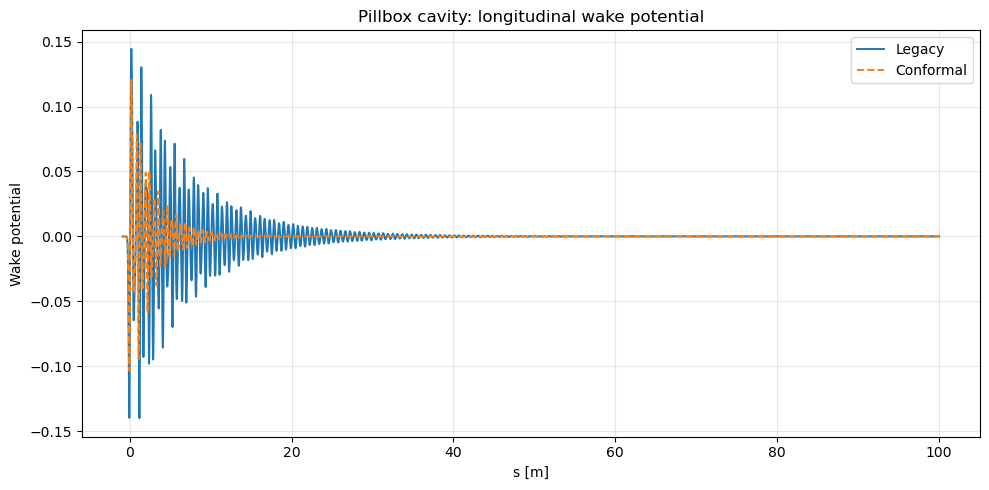

In [75]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    wake_legacy.s,
    wake_legacy.WP,
    linewidth=1.4,
    label="Legacy",
)

ax.plot(
    wake_conformal.s,
    wake_conformal.WP,
    linewidth=1.4,
    linestyle="--",
    label="Conformal",
)

ax.set_xlabel("s [m]")
ax.set_ylabel("Wake potential")
ax.set_title("Pillbox cavity: longitudinal wake potential")
ax.grid(True, alpha=0.3)
ax.legend()

fig.tight_layout()
plt.show()

## Longitudinal impedance comparison

The magnitude is the most convenient first comparison because shifts in the
cavity resonances become immediately visible.


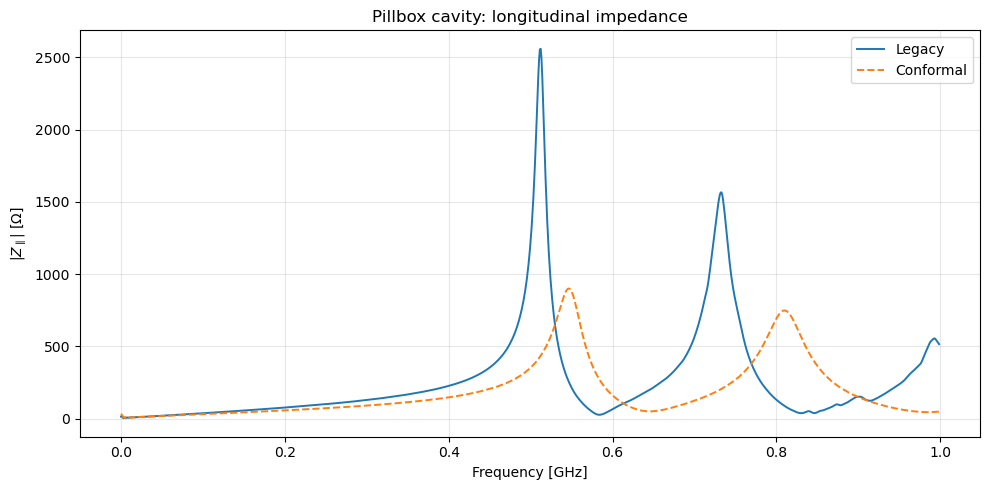

In [76]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    wake_legacy.f / 1e9,
    np.abs(wake_legacy.Z),
    linewidth=1.4,
    label="Legacy",
)

ax.plot(
    wake_conformal.f / 1e9,
    np.abs(wake_conformal.Z),
    linewidth=1.4,
    linestyle="--",
    label="Conformal",
)

ax.set_xlabel("Frequency [GHz]")
ax.set_ylabel(r"$|Z_\parallel|$ [$\Omega$]")
ax.set_title("Pillbox cavity: longitudinal impedance")
ax.grid(True, alpha=0.3)
ax.legend()

fig.tight_layout()
plt.show()

## Real and imaginary parts

This plot helps distinguish an actual resonance-frequency shift from a change
only in peak magnitude.


In [ ]:
fig, axes = plt.subplots(
    2,
    1,
    figsize=(10, 8),
    sharex=True,
)

axes[0].plot(
    wake_legacy.f / 1e9,
    np.real(wake_legacy.Z),
    linewidth=1.3,
    label="Legacy",
)

axes[0].plot(
    wake_conformal.f / 1e9,
    np.real(wake_conformal.Z),
    linewidth=1.3,
    linestyle="--",
    label="Conformal",
)

axes[0].set_ylabel(r"Re$(Z_\parallel)$ [$\Omega$]")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(
    wake_legacy.f / 1e9,
    np.imag(wake_legacy.Z),
    linewidth=1.3,
    label="Legacy",
)

axes[1].plot(
    wake_conformal.f / 1e9,
    np.imag(wake_conformal.Z),
    linewidth=1.3,
    linestyle="--",
    label="Conformal",
)

axes[1].set_xlabel("Frequency [GHz]")
axes[1].set_ylabel(r"Im$(Z_\parallel)$ [$\Omega$]")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

fig.suptitle("Pillbox cavity: longitudinal impedance")
fig.tight_layout()
plt.show()

## Relative differences

These diagnostics are normalized by the maximum magnitude of the legacy
solution rather than pointwise, so zeros in the wake or impedance do not
artificially produce huge relative errors.


In [ ]:
if np.array_equal(wake_legacy.s, wake_conformal.s):
    wake_difference = wake_conformal.WP - wake_legacy.WP
    wake_relative_difference = wake_difference / max(
        np.max(np.abs(wake_legacy.WP)), 1e-30
    )

    fig, ax = plt.subplots(figsize=(10, 4))

    ax.plot(
        wake_legacy.s,
        wake_relative_difference,
    )

    ax.set_xlabel("s [m]")
    ax.set_ylabel(
        r"$(W_\mathrm{conf}-W_\mathrm{legacy})/"
        r"\max|W_\mathrm{legacy}|$"
    )
    ax.set_title("Normalized wake-potential difference")
    ax.grid(True, alpha=0.3)

    fig.tight_layout()
    plt.show()
else:
    print("Wake axes differ; direct pointwise wake subtraction was skipped.")

In [ ]:
if np.array_equal(wake_legacy.f, wake_conformal.f):
    impedance_difference = np.abs(wake_conformal.Z) - np.abs(wake_legacy.Z)

    impedance_relative_difference = impedance_difference / max(
        np.max(np.abs(wake_legacy.Z)), 1e-30
    )

    fig, ax = plt.subplots(figsize=(10, 4))

    ax.plot(
        wake_legacy.f / 1e9,
        impedance_relative_difference,
    )

    ax.set_xlabel("Frequency [GHz]")
    ax.set_ylabel(
        r"$(|Z|_\mathrm{conf}-|Z|_\mathrm{legacy})/"
        r"\max|Z_\mathrm{legacy}|$"
    )
    ax.set_title("Normalized impedance-magnitude difference")
    ax.grid(True, alpha=0.3)

    fig.tight_layout()
    plt.show()
else:
    print("Frequency axes differ; direct pointwise impedance subtraction was skipped.")